# Fitting your own measurement

To analyse measured data you need three things besides the material model:

1. the **counts** of the sample measurement, histogrammed on the time grid of
   one period and summed over all periods,
2. the **open beam of one pulse**, from a separate calibration with one short
   pulse per period, with much better statistics than the sample measurement
   (for example summed over the whole detector), and
3. the **pulse pattern**, as programmed in the chopper.

Here the 'measured' data are simulated and written to CSV files, then read
back as you would read your own.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbragg
import frame_overlap as fo

# the material, as in nbragg: 2 cm of alpha-iron
xs = nbragg.CrossSection(materials={"iron": {"mat": "Fe_sg229_Iron-alpha.ncmat"}})
model = nbragg.TransmissionModel(xs, response="jorgensen_inv", tof_length=9.0, vary_response=False)
model.params["thickness"].set(value=2.0)     # cm
model.params["α0"].set(value=3000.0)         # moderator response (rise), close to a water moderator
model.params["β0"].set(value=50.0)           # moderator response (decay)
sample = fo.Sample(model, free=["thickness", "strain"])

# the instrument: 9 m flight path, 50 ms period, 10 us bins, a thermal moderator
grid = fo.TimeGrid(flight_path=9.0, frequency=20.0, bin_width=10e-6)
beam = fo.OpenBeam.maxwellian(grid, flux=5e6, area=0.03)
hours = 8

In [2]:
import pandas as pd
pattern = fo.Pattern.times([0.0, 11.97e-3, 22.33e-3, 35.48e-3], width=200e-6)
truth = fo.Experiment(sample.with_values(thickness=1.95), beam, pattern, time=hours * 3600)
sim = truth.simulate(seed=7)
pd.DataFrame(dict(time_s=grid.t, counts=sim.counts)).to_csv("my_sample_counts.csv", index=False)
# calibration: one 10 us pulse per period for 8 h, summed over a detector area 100 times larger
calib = fo.Experiment(sample.with_values(thickness=0.0), beam.scaled(100), fo.Pattern.single(10e-6), time=8 * 3600)
pd.DataFrame(dict(time_s=grid.t, counts=calib.simulate(seed=1).counts)).to_csv(
    "my_open_beam_one_pulse.csv", index=False)
print("written two CSV files")

written two CSV files


## Read the data and fit

In [3]:
counts = pd.read_csv("my_sample_counts.csv").counts.values
ob = pd.read_csv("my_open_beam_one_pulse.csv").counts.values
open_beam = fo.OpenBeam.from_counts(grid, ob, pulse_width=10e-6, time=8 * 3600).scaled(1 / 100)
data = fo.Measurement(grid, counts, pattern, open_beam, time=hours * 3600)
result = fo.RietveldFit(window=(1.0, 5.0)).fit(data, sample)     # starts from the sample's 2.0 cm
print(result.fit_report())
result.to_dataframe()

[[Rietveld fit]]
    converged after 11 evaluations
    deviance per bin = 1.037 (5000 bins with counts)
[[Parameters]]
    thickness         1.94962 +/- 0.000431
    strain       -3.84348e-05 +/- 8.73e-05  = -38.4 +/- 87.3 microstrain


,parameter,value,error,value_microstrain,error_microstrain
0,thickness,1.949618,0.000431,NaN,NaN
1,strain,-0.000038,0.000087,-38.434755,87.275416


## Check the fit

The deviance per bin should be close to one, and the residuals should look
like noise. The true thickness of the simulation was 1.95 cm.

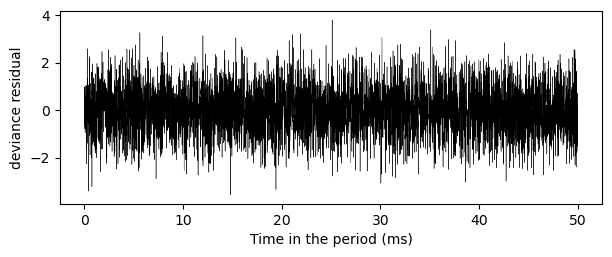

deviance per bin: 1.037


In [4]:
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(grid.t * 1e3, result.residuals(), lw=0.3, color="k")
ax.set_xlabel("Time in the period (ms)"); ax.set_ylabel("deviance residual")
plt.show()
print("deviance per bin:", round(result.deviance / result.n_used, 3))

## A background

A constant count background (room background, detector noise) can be given
to the Measurement if it is known (``background=``, counts per bin and
second), or fitted. Here the simulated data have none, and the fitted value
is consistent with zero.

In [5]:
with_bg = fo.RietveldFit(window=(1.0, 5.0), fit_background=True).fit(data, sample)
print(with_bg.fit_report())

[[Rietveld fit]]
    converged after 6 evaluations
    deviance per bin = 1.037 (5000 bins with counts)
[[Parameters]]
    thickness         1.94964 +/- 0.000431
    strain       -4.11661e-05 +/- 8.73e-05  = -41.2 +/- 87.3 microstrain
    background   -7.02929e-05 +/- 6.86e-05


The fit treats the open beam as exact. Its own noise adds to the
uncertainty of the result, so check its effect, for example by refitting with
the open beam of half the calibration data, and keep its statistics well
above those of the sample measurement.